# Delay–Doppler simulation：新版绝对时延代码审查与复现实验

来源：`delay_doppler_simu_precision_2.ipynb`。原 `_2` 文件保留不动，本笔记本替换上次 reviewed 入口。

新版只改了单元 7 的训练／测试波形时延：两路分别使用 `K0`、`K1`，接收机仍估计它们的差。本版保留该改动，并使用覆盖绝对时延的保护区、float64 一致真值、匹配 FIR 的精细化和分支噪声白化。共同波形是固定符号时钟的 QPSK/RRC；不能把其二阶统计一概当成平稳。

**原 exact CRB 的导数遗漏仍存在，因此不用于结果图；图中仅保留明确标注的近似信息参考。** 完整代码流程、问题证据和最新结果见 `overleaf_paper/main_explained_zh.md` 第 13–16 节。

使用前请重启内核并从头运行，避免复用上一版已导入的 Python 模块。默认读取已完成的实验，重新 Monte Carlo 需启用下方开关。


In [1]:
from pathlib import Path
import sys, json, csv, os, hashlib
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"
root = Path.cwd().resolve()
if root.name == "overleaf_paper":
    root = root.parent
assert (root / "overleaf_paper" / "tools").is_dir(), "Run from the project or overleaf_paper directory."
tools_path = root / "overleaf_paper" / "tools"
if str(tools_path) not in sys.path:
    sys.path.insert(0, str(tools_path))
import numpy as np
from IPython.display import Image, Markdown, display
try:
    from threadpoolctl import threadpool_limits
except ImportError:
    from contextlib import nullcontext
    def threadpool_limits(limits=1):
        return nullcontext()
from precision_review import setup, run, summarize, OUT, NAMES, SOURCE_NOTEBOOK
print("Source:", SOURCE_NOTEBOOK.name)
print("Results:", OUT)

Source: delay_doppler_simu_precision_2.ipynb
Results: /home/shizhen/my_project/Anti-jamming-unsync/overleaf_paper/paper_assets/precision_review


## 1. 版本差异、信道与绝对时延

单元 0–6 与前版源码完全相同，所以复用原先固定发射波束的 1536 点 Sionna 信道。当前采样率为 585937.5 Hz，每 3 点对应一个 5.12 微秒 FFT block。

两路绝对时延约为 759.6071782、1026.0767340 个样本，相对时延为 266.4695558。所有换算先提升到 float64，生成和误差统计共享同一真值。保护区改为每边 1140 点，总长 3816 点；两路延迟窗口均在序列内部。长序列频域成形依然是周期近似。

`received_signals(X, context)` 对同一波形分别做两个绝对时延，再乘包含绝对 Doppler 的信道增益；不能额外重复乘同一个 Doppler。

In [2]:
REGENERATE_CHANNEL = False
if REGENERATE_CHANNEL:
    import subprocess
    subprocess.run([sys.executable, str(tools_path / "prepare_precision_channel.py")], cwd=root, check=True)
audit = json.loads((OUT / "source_audit.json").read_text())
assert hashlib.sha256(SOURCE_NOTEBOOK.read_bytes()).hexdigest() == audit["source_sha256"], "Source notebook changed; review the new changes before reusing this audit."
context = setup()
print(json.dumps({key: value for key, value in context.items() if key != "gains"}, indent=2))
print("Changed source cells:", audit["changed_source_cells"])

{
  "delay": 266.4695557541563,
  "absolute_delays_samples": [
    759.6071782245417,
    1026.076733978698
  ],
  "delay_model": "per-branch absolute delays; fixed symbol-clock phase",
  "long_record_samples": 3816,
  "guard_samples": 1140,
  "freq": -0.013440987401222418,
  "fs": 585937.5,
  "nv": 1222,
  "ratio": 0.3802435591643376,
  "cells": 52972.907333333336
}
Changed source cells: [7]


## 2. 数值实现与模型检查

检查 FFT 搜索与直接互相关、解析梯度与有限差分、无噪声精细化、真值残余、原 CRB 缺失导数。另检查绝对／相对时延一致、窗口未回绕，以及移动参考波形后的等价表达。

`expected_sample_phase_powers` 从脉冲系数独立计算三个符号相位上的期望功率。它们平均为 1，但逐相位不同，说明固定符号时钟的 QPSK/RRC 是循环平稳；这也是论文中“公共时延无关”只适用于平稳近似的原因。

In [3]:
from check_precision import main as check
with threadpool_limits(limits=1):
    check()


{
  "fft_direct_p1": 7.301383692758483e-14,
  "fft_direct_p4": 4.657208068192199e-14,
  "gradient_relative_error": 1.4622113656685892e-09,
  "absolute_delays_samples": [
    759.6071782245417,
    1026.076733978698
  ],
  "absolute_relative_consistency": 0.0,
  "source_window_bounds": [
    [
      380.3928217754583,
      1915.3928217754583
    ],
    [
      113.92326602130197,
      1648.923266021302
    ]
  ],
  "long_record_samples": 3816,
  "absolute_rebased_relative_error": 5.2120817739210916e-14,
  "expected_sample_phase_powers": {
    "zero": [
      1.1591536486424394,
      0.9204231756787811,
      0.9204231756787804
    ],
    "branch0": [
      1.046900096051815,
      1.1082606146020608,
      0.844839289346124
    ],
    "branch1": [
      1.1571027494524224,
      0.9435044066704634,
      0.8993928438771153
    ]
  },
  "noiseless_polish_delay_error": -9.992126024371828e-07,
  "noiseless_polish_bin_error": -3.991472379283323e-07,
  "noiseless_oracle_inr": 3.3917101506

## 3. Monte Carlo：同步 → 白化选权重 → 独立测试

每个输入功率 120 次试验，每次 32 个独立测试块。密集 `p=4` 用 zoom 初始化；稀疏 `p=1, K=1/3` 用 10 次梯度初始化；三者最终调用同一个 `matched_polish`，优化真正抵消时使用的去旋转 → FIR 算子。`weights` 对齐后先做分支噪声白化，再取最小特征向量。

`oracle` 只知道同步真值，仍需从有噪训练数据估计权重。另四种步长曲线是固定 10 次梯度且无最终精细化的消融，不等于收敛算法比较。不同方法共享训练与测试波形，不同功率点共享随机数。

默认验证并加载已保存结果。设 `RUN_MONTE_CARLO=True` 重跑；若重建了信道，也必须重跑。论文引用独立、包含候选提取的完整耗时基准，而不是逐 trial 的诊断计时。

In [4]:
RUN_MONTE_CARLO = False
GAMMA0_DB = np.array([-25,-20,-15,-12,-10,-9,-8,-7.5,-7,-6.5,-6,-5.5,-5,-4,-2,0,5,8.98,10,20,30,40,50,60], float)
if RUN_MONTE_CARLO:
    with threadpool_limits(limits=1):
        run(GAMMA0_DB, trials=120, test_blocks=32)
        from benchmark_precision import main as benchmark
        benchmark()
else:
    config = json.loads((OUT / "run_config.json").read_text())
    assert config.get("schema_version") == 2, "Rerun the absolute-delay experiment before plotting."
    assert config["source_notebook_sha256"] == hashlib.sha256(SOURCE_NOTEBOOK.read_bytes()).hexdigest()
    assert config["channel_sha256"] == hashlib.sha256((OUT / "channel.npz").read_bytes()).hexdigest(), "Channel changed: rerun Monte Carlo."
    for name, expected in config["source_sha256"].items():
        if name == "plot_precision_review.py":
            continue  # Presentation changes do not invalidate numerical trials.
        assert hashlib.sha256((tools_path / name).read_bytes()).hexdigest() == expected, f"{name} changed: rerun or review provenance."
    data = np.load(OUT / "trials.npz")
    assert data["raw"].shape == (len(GAMMA0_DB), 120, len(NAMES), 5)
    assert np.array_equal(data["gamma_db"], GAMMA0_DB)
    assert np.isfinite(data["raw"]).all()
    summarize()
print("Verified absolute-delay results:", OUT / "trials.npz")

Verified absolute-delay results: /home/shizhen/my_project/Anti-jamming-unsync/overleaf_paper/paper_assets/precision_review/trials.npz


## 4. 结果图与导出

所有曲线从本次保存的逐 trial 数据生成，覆盖论文中的三组 PDF/PNG 和结果表。先平均线性残余功率，再转 dB；bootstrap 给出残余均值区间，Wilson 区间描述误检概率。RMSE 同时报告无条件统计和仅正确检测的条件统计；条件 RMSE 不能严格验证无条件无偏界。

图中 `Surrogate CRB scale` 是近似信息模型的尺度参考，不是修复并重算后的精确 CRB。

双子图统一上下排列，按 IEEE 单栏宽度导出并压缩图高。绘图源码和数据哈希单独记入 `figure_manifest.json`，排版调整不需要重跑 Monte Carlo。


Generated three figure pairs and result_table.tex from recorded trials.


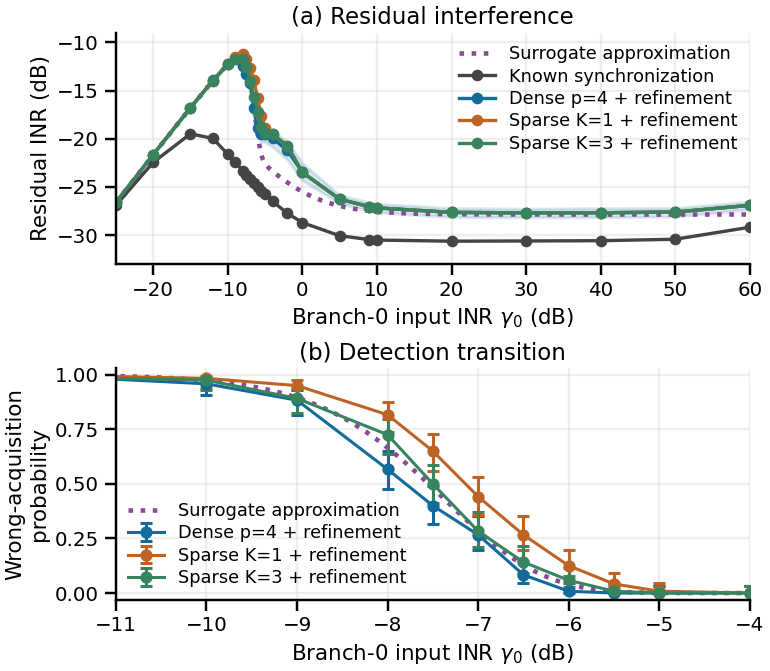

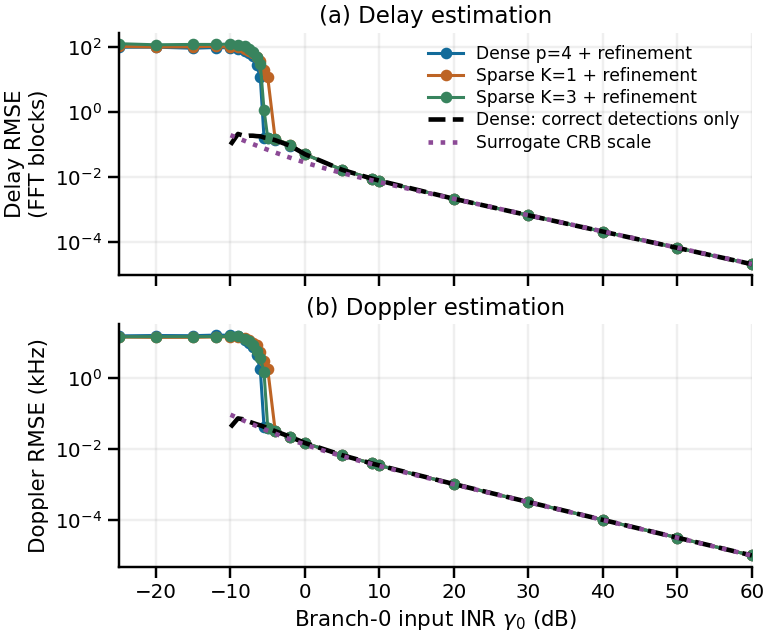

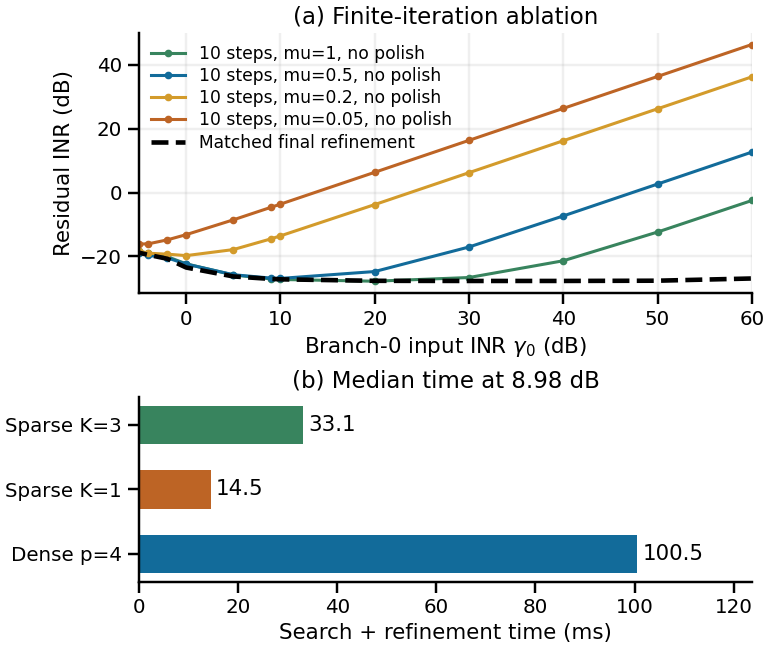

In [5]:
from plot_precision_review import main as plot
plot()
for name in ["mc_inr_detection", "mc_estimation", "mc_ablation_runtime"]:
    display(Image(filename=str(OUT / (name + ".png"))))


In [6]:
with (OUT / "summary.csv").open() as handle:
    rows = list(csv.DictReader(handle))
selected = [r for r in rows if float(r["gamma0_db"]) in [-7, 8.98, 40, 60] and r["algorithm"] in NAMES[:4]]
header = "| gamma0 (dB) | method | INR (dB) | Pwrong |\n|---|---|---|---|\n"
body = "\n".join(f"| {r['gamma0_db']} | {r['algorithm']} | {float(r['inr_db']):.2f} | {float(r['p_wrong']):.3f} |" for r in selected)
display(Markdown(header + body))

print("Inclusive timing benchmark:")
print(json.loads((OUT / "timing_benchmark.json").read_text())["median_ms"])


| gamma0 (dB) | method | INR (dB) | Pwrong |
|---|---|---|---|
| -7.0 | oracle | -24.16 | 0.000 |
| -7.0 | dense_p4 | -14.17 | 0.267 |
| -7.0 | sparse_k1 | -12.61 | 0.442 |
| -7.0 | sparse_k3 | -14.03 | 0.283 |
| 8.98 | oracle | -30.46 | 0.000 |
| 8.98 | dense_p4 | -27.05 | 0.000 |
| 8.98 | sparse_k1 | -27.05 | 0.000 |
| 8.98 | sparse_k3 | -27.05 | 0.000 |
| 40.0 | oracle | -30.58 | 0.000 |
| 40.0 | dense_p4 | -27.68 | 0.000 |
| 40.0 | sparse_k1 | -27.68 | 0.000 |
| 40.0 | sparse_k3 | -27.68 | 0.000 |
| 60.0 | oracle | -29.18 | 0.000 |
| 60.0 | dense_p4 | -26.91 | 0.000 |
| 60.0 | sparse_k1 | -26.91 | 0.000 |
| 60.0 | sparse_k3 | -26.91 | 0.000 |

Inclusive timing benchmark:
{'dense_p4': 100.54600349394605, 'sparse_k1': 14.528233499731869, 'sparse_k3': 33.09813697705977}
